In [ ]:
import os
import re
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
#建立data資料夾
os.makedirs("data", exist_ok=True)
#下載IMDb
url="http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
filepath="data/aclImdb_v1.tar.gz"
if not os.path.isfile(filepath):
    result=urllib.request.urlretrieve(url,filepath)
    print('downloaded:',result)

In [ ]:
#解壓縮IMDb
if not os.path.exists("data/aclImdb"):
    with tarfile.open(filepath, 'r:gz') as tfile:
        tfile.extractall('data/')

In [ ]:
#定義rm_tags(text)函數
def rm_tags(text):
    re_tag = re.compile(r'<[^>]+>')
    return re_tag.sub('', text)

In [ ]:
#定義 read_files(filetype)函數
def read_files(filetype):
    path = "data/aclImdb/"
    file_list=[]

    positive_path=path + filetype+"/pos/"
    for f in os.listdir(positive_path):
        file_list+=[positive_path+f]

    negative_path=path + filetype+"/neg/"
    for f in os.listdir(negative_path):
        file_list+=[negative_path+f]

    print('read',filetype, 'files:',len(file_list))

    all_labels = ([1] * 12500 + [0] * 12500)

    all_texts  = []
    for fi in file_list:
        with open(fi,encoding='utf8') as file_input:
            all_texts += [rm_tags(" ".join(file_input.readlines()))]

    return all_labels,all_texts

In [ ]:
#建立訓練與測試資料
y_train, train_text = read_files("train")
y_test, test_text = read_files("test")

read train files: 25000
read test files: 25000


In [ ]:
#建立字典與文字轉固定長度數字序列

NUM_WORDS = 2000#字典字數
MAX_LEN = 100#向量串長度

tokenizer = Tokenizer(num_words=NUM_WORDS)
tokenizer.fit_on_texts(train_text)
print('字典文件總數:', tokenizer.document_count)
print('字典前10項:', list(tokenizer.word_index.items())[:10])

# 轉換為數字串
x_train_seq = tokenizer.texts_to_sequences(train_text)
x_test_seq  = tokenizer.texts_to_sequences(test_text)

# 補零或截減使每篇長度皆為100
x_train = pad_sequences(x_train_seq, maxlen=MAX_LEN)
x_test  = pad_sequences(x_test_seq,  maxlen=MAX_LEN)

y_train = np.array(y_train)
y_test  = np.array(y_test)

np.random.seed(42)
indices = np.arange(len(x_train))
np.random.shuffle(indices)
x_train = x_train[indices]
y_train = y_train[indices]

字典文件總數: 25000
字典前10項: [('the', 1), ('and', 2), ('a', 3), ('of', 4), ('to', 5), ('is', 6), ('in', 7), ('it', 8), ('i', 9), ('this', 10)]


In [ ]:
#建立神經網路模型
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

EMBEDDING_DIM = 32
LSTM_UNITS = 16

model = Sequential([

    Embedding(input_dim=NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    #Embedding層：
    #Input shape: (None, 100)
    #Output shape: (None, 100, 32)
    #參數計算    : 2000 * 32 = 64,000

    LSTM(units=LSTM_UNITS),
    #LSTM 層：
   #Input shape: (None, 100, 32)
  #Output shape: (None, 16)
   #參數計算:4*[48 * 16 +16] = 4 * 784 = 3,136

    Dropout(0.5),

    Dense(units=1, activation='sigmoid')
     #Dense 層：
    #Input shape: (None, 16)
    #Output shape: (None, 1)
   #參數計算: 16*1 + 1 = 17
])

model.build(input_shape=(None, MAX_LEN))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 32)        │        64,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,153 (262.32 KB)

 Trainable params: 67,153 (262.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#訓練模型

model.compile(loss='binary_crossentropy',optimizer='adam',
              metrics=['accuracy'])
train_history = model.fit(x_train, y_train,
              batch_size=128,
              epochs=10,
              verbose=2,
              validation_split=0.2)

Epoch 1/10
157/157 - 7s - 46ms/step - accuracy: 0.6974 - loss: 0.5696 - val_accuracy: 0.8324 - val_loss: 0.3879
Epoch 2/10
157/157 - 5s - 32ms/step - accuracy: 0.8528 - loss: 0.3639 - val_accuracy: 0.8396 - val_loss: 0.3621
Epoch 3/10
157/157 - 4s - 29ms/step - accuracy: 0.8681 - loss: 0.3257 - val_accuracy: 0.8442 - val_loss: 0.3528
Epoch 4/10
157/157 - 6s - 39ms/step - accuracy: 0.8766 - loss: 0.3081 - val_accuracy: 0.8442 - val_loss: 0.3663
Epoch 5/10
157/157 - 5s - 31ms/step - accuracy: 0.8872 - loss: 0.2844 - val_accuracy: 0.8516 - val_loss: 0.3577
Epoch 6/10
157/157 - 6s - 37ms/step - accuracy: 0.8898 - loss: 0.2753 - val_accuracy: 0.8472 - val_loss: 0.3573
Epoch 7/10
157/157 - 5s - 35ms/step - accuracy: 0.8960 - loss: 0.2622 - val_accuracy: 0.8436 - val_loss: 0.3853
Epoch 8/10
157/157 - 6s - 36ms/step - accuracy: 0.9003 - loss: 0.2518 - val_accuracy: 0.8410 - val_loss: 0.3735
Epoch 9/10
157/157 - 5s - 30ms/step - accuracy: 0.9063 - loss: 0.2384 - val_accuracy: 0.8462 - val_loss:

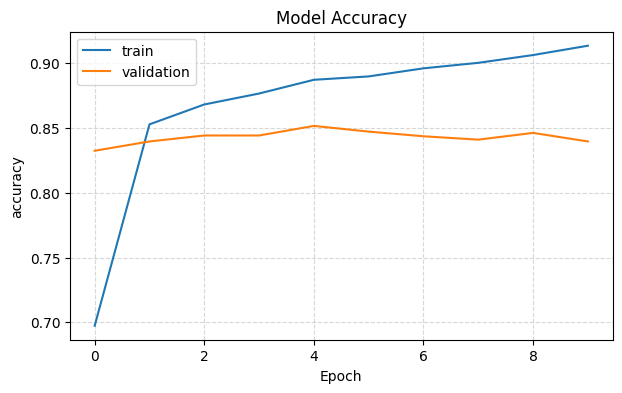

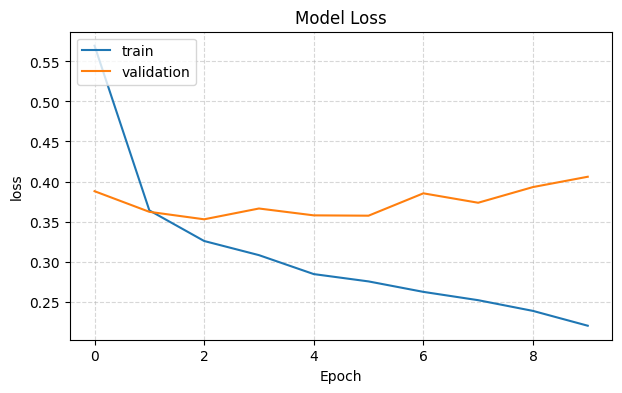

In [ ]:
#Loss和Accuracy折線圖
import matplotlib.pyplot as plt

def show_train_history(history, train_metric, val_metric, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history.history[train_metric], label='train')
    plt.plot(history.history[val_metric], label='validation')
    plt.title(title)
    plt.ylabel(train_metric)
    plt.xlabel('Epoch')
    plt.legend(loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

show_train_history(train_history, 'accuracy', 'val_accuracy', 'Model Accuracy')
show_train_history(train_history, 'loss', 'val_loss', 'Model Loss')


In [ ]:
#評估模型準確率
scores = model.evaluate(x_test, y_test, verbose=1)
print(f"Test Loss: {scores[0]:.4f}")
print(f"Test Accuracy: {scores[1]:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8420 - loss: 0.3940
Test Loss: 0.3940
Test Accuracy: 0.8420


In [ ]:
import pickle
from google.colab import drive
# 儲存完整模型
model.save("imdb_lstm_model.keras")
# 儲存模型權重
model.save_weights("imdb_lstm.weights.h5")
# 儲存tokenizer
drive.mount('/content/drive')
save_path = '/content/drive/My Drive/python github/'
model.save(save_path + "imdb_lstm_model.keras")
model.save_weights(save_path + "imdb_lstm.weights.h5")
with open(save_path + "imdb_tokenizer.pickle", "wb") as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
